In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm


In [2]:
DATA = Path("../data")
print(DATA.resolve())

C:\Zahra\projects\weather-shift-segmentation-2026\weather-shift-segmentation\data


In [3]:
cs_images = sorted((DATA/ "cityscapes"/ "leftImg8bit"/ "val").rglob("*.png"))
print(len(cs_images))
print(cs_images[0])

500
..\data\cityscapes\leftImg8bit\val\frankfurt\frankfurt_000000_000294_leftImg8bit.png


In [4]:
cs_labels = sorted((DATA/ "cityscapes"/ "gtFine"/ "val").rglob("*_labelIds.png"))
print(len(cs_labels))
print(cs_labels[0])

500
..\data\cityscapes\gtFine\val\frankfurt\frankfurt_000000_000294_gtFine_labelIds.png


In [5]:
for condition in ["fog", "night", "rain", "snow"]:
    folder = DATA/ "acdc"/ "rgb_anon"/ condition/ "val"
    print(condition, len(list(folder.rglob("*.png"))))

fog 100
night 106
rain 100
snow 100


In [6]:
print(cs_images[0].name)
print(cs_labels[0].name)

frankfurt_000000_000294_leftImg8bit.png
frankfurt_000000_000294_gtFine_labelIds.png


In [7]:
img = Image.open(cs_images[0])

# Turn the label image into a grid of numbers
label = np.array(Image.open(cs_labels[0]))

print(img.size, label.shape, label.dtype)

(2048, 1024) (1024, 2048) uint8


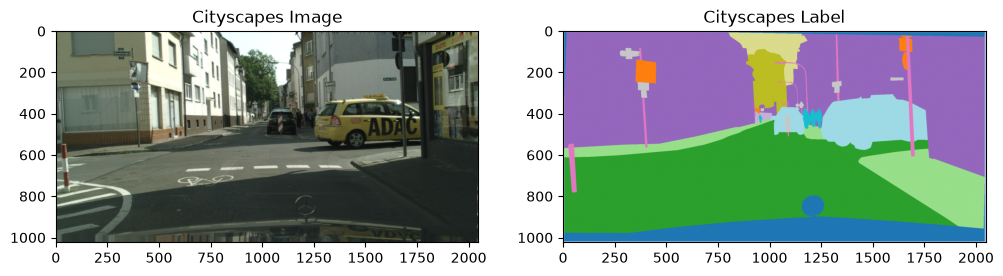

In [8]:
plt.subplots(1, 2, figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Cityscapes Image")

plt.subplot(1, 2, 2)
plt.imshow(label, cmap="tab20")
plt.title("Cityscapes Label")

plt.show()

In [9]:
print(np.unique(label))

[ 1  2  3  4  7  8 11 13 17 20 21 23 24 26]


In [10]:
gt_fog = sorted((DATA/ "acdc"/ "gt"/ "fog"/ "val").rglob("*"))

for f in gt_fog[:8]:
    print(f.name)

GOPR0476
GOPR0476_frame_000761_gt_invGray.png
GOPR0476_frame_000761_gt_invIds.png
GOPR0476_frame_000761_gt_labelColor.png
GOPR0476_frame_000761_gt_labelIds.png
GOPR0476_frame_000761_gt_labelTrainIds.png
GOPR0476_frame_000769_gt_invGray.png
GOPR0476_frame_000769_gt_invIds.png


In [11]:
rgb_anon_fog = sorted((DATA/ "acdc"/ "rgb_anon"/ "fog"/ "val").rglob("*"))
for f in rgb_anon_fog[:8]:
    print(f.name)

GOPR0476
GOPR0476_frame_000761_rgb_anon.png
GOPR0476_frame_000769_rgb_anon.png
GOPR0476_frame_000775_rgb_anon.png
GOPR0476_frame_000781_rgb_anon.png
GOPR0476_frame_000788_rgb_anon.png
GOPR0476_frame_000798_rgb_anon.png
GOPR0476_frame_000826_rgb_anon.png


In [12]:
# Official Cityscapes table: label ID -> train ID (everything else = 255, ignore)
ID_TO_TRAINID = {
  7: 0,
  8: 1,
  11: 2,
  12: 3,
  13: 4,
  17: 5,
  19: 6,
  20: 7,
  21: 8,
  22: 9,
  23: 10,
  24: 11,
  25: 12,
  26: 13,
  27: 14,
  28: 15,
  31: 16,
  32: 17,
  33: 18
}

In [13]:
lut = np.full(256, 255, dtype=np.uint8)

for label_id, train_id in ID_TO_TRAINID.items():
    lut[label_id] = train_id

train_label = lut[label]
print(np.unique(train_label))

[  0   1   2   4   5   7   8  10  11  13 255]


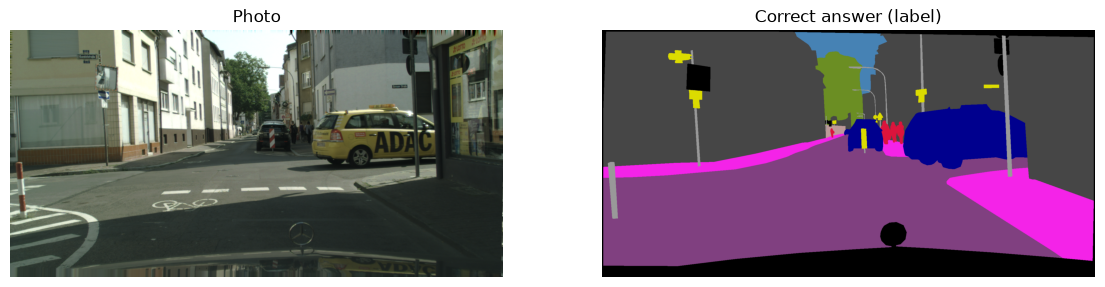

In [14]:
palette = np.array([
    [128, 64, 128],   # 0 - road
    [244, 35, 232],   # 1 - sidewalk
    [70, 70, 70],     # 2 - building
    [102, 102, 156],  # 3 - wall
    [190, 153, 153],  # 4 - fence
    [153, 153, 153],  # 5 - pole
    [250, 170, 30],   # 6 - traffic light
    [220, 220, 0],    # 7 - traffic sign
    [107, 142, 35],   # 8 - vegetation
    [152, 251, 152],  # 9 - terrain
    [70, 130, 180],   # 10 - sky
    [220, 20, 60],    # 11 - person
    [255, 0, 0],      # 12 - rider
    [0, 0, 142],      # 13 - car
    [0, 0, 70],       # 14 - truck
    [0, 60, 100],     # 15 - bus
    [0, 80, 100],     # 16 - train
    [0, 0, 230],      # 17 - motorcycle
    [119, 11, 32]    # 18 - bicycle
], dtype=np.uint8)

# add a 20th colour (black) for "ignore"
palette_ext = np.vstack([palette, [0, 0, 0]])

# send ignored pixels (255) to that new black colour (position 19)
show = np.where(train_label == 255, 19, train_label)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(img);                ax[0].set_title("Photo")
ax[1].imshow(palette_ext[show]);  ax[1].set_title("Correct answer (label)")
for a in ax:
    a.axis("off")

In [15]:
%load_ext autoreload
%autoreload 2

from weather_shift.data import get_pairs

pairs = get_pairs("../data", "cityscapes")
print(len(pairs), all(label.exists() for _, label in pairs))

for condition in ["fog", "night", "rain", "snow"]:
    pairs = get_pairs("../data", "acdc", condition)
    print(condition, len(pairs), all(label.exists() for _, label in pairs))

500 True
fog 100 True
night 106 True
rain 100 True
snow 100 True


In [16]:
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor
from weather_shift.data import get_pairs, load_label
from weather_shift.model import predict

name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(name)
model = SegformerForSemanticSegmentation.from_pretrained(name).eval()

# Test the model on a single image
pairs = get_pairs("../data", "cityscapes")
image_path , label_path = pairs[0]
image = Image.open(image_path).convert("RGB")
label = load_label(label_path)
pred, conf = predict(image, processor, model)
print(label.shape, pred.shape)

c:\Zahra\projects\weather-shift-segmentation-2026\weather-shift-segmentation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 208/208 [00:00<00:00, 30794.75it/s]


(1024, 2048) (1024, 2048)


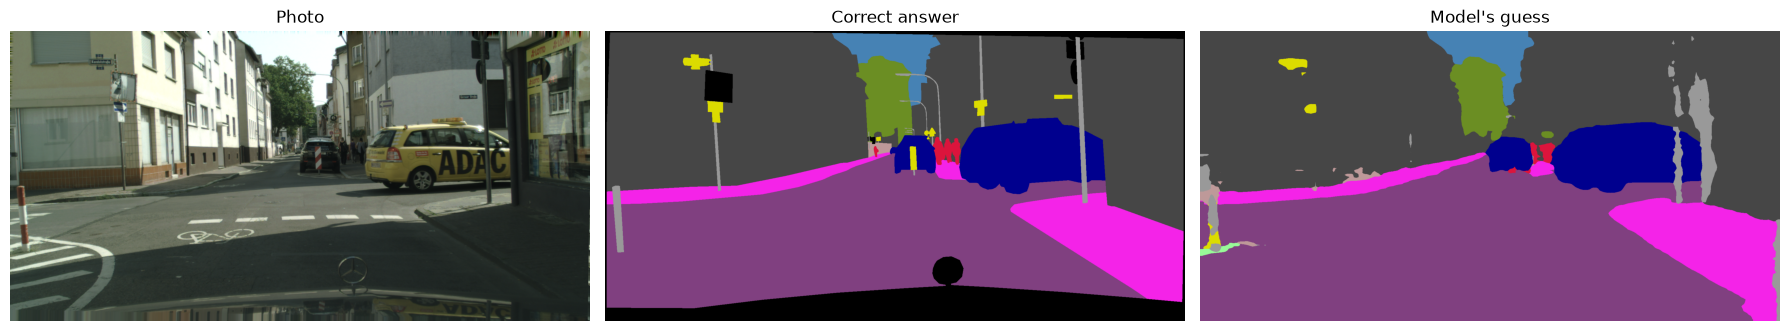

In [17]:
label_show = np.where(label == 255, 19, label)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(image)
axes[0].set_title("Photo")
axes[1].imshow(palette_ext[label_show])
axes[1].set_title("Correct answer")
axes[2].imshow(palette[pred])
axes[2].set_title("Model's guess")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [18]:
# mIoU pair[0]

valid = label != 255
ious = []

for c in range(19):
    true_c = (label == c) & valid
    pred_c = (pred == c) & valid
    inter = (true_c & pred_c).sum()
    union = (true_c | pred_c).sum()
    if union > 0:
        iou = inter / union
        ious.append(iou)
        print(f"{model.config.id2label[c]:15s} {iou:.3f}")

print(f"mIoU: {round(np.mean(ious), 3)}")

road            0.967
sidewalk        0.855
building        0.916
fence           0.000
pole            0.182
traffic sign    0.260
vegetation      0.867
terrain         0.000
sky             0.934
person          0.444
car             0.895
mIoU: 0.575


In [19]:
from weather_shift.metrics import evaluate

ious = evaluate(pairs, processor, model)
print(f"mIoU: {round(ious.mean(), 3)}")

100%|██████████| 500/500 [04:37<00:00,  1.80it/s]

mIoU: 0.582


In [20]:
# Evaluate the model on each class and condition
# mIoU for each class and condition
results ={}

results["clear"] = evaluate(get_pairs("../data", "cityscapes"), processor, model)

conditions = ["fog" , "night", "rain", "snow"]
for cond in conditions:
    results[cond] = evaluate(get_pairs("../data", "acdc", cond), processor, model)

class_names = [model.config.id2label[c] for c in range(19)]
table = pd.DataFrame(results, index=class_names)
table.loc["mIoU"] = table.mean()

print(table.round(3))
table.to_csv("../reports/week2_iou_per_class.csv")

100%|██████████| 100/100 [00:52<00:00,  1.91it/s]

               clear    fog  night   rain   snow
road           0.963  0.925  0.761  0.721  0.729
sidewalk       0.736  0.696  0.170  0.296  0.267
building       0.862  0.781  0.416  0.787  0.700
wall           0.438  0.439  0.115  0.103  0.219
fence          0.377  0.374  0.265  0.177  0.271
pole           0.313  0.446  0.300  0.327  0.309
traffic light  0.349  0.581  0.226  0.501  0.562
traffic sign   0.474  0.454  0.124  0.393  0.408
vegetation     0.871  0.838  0.549  0.870  0.761
terrain        0.572  0.524  0.178  0.455  0.097
sky            0.913  0.959  0.005  0.962  0.931
person         0.541  0.235  0.136  0.365  0.332
rider          0.252  0.290  0.000  0.000  0.000
car            0.870  0.808  0.259  0.718  0.680
truck          0.546  0.745  0.000  0.086  0.359
bus            0.590  0.905  0.000  0.289  0.029
train          0.509  0.845  0.416  0.175  0.491
motorcycle     0.333  0.421  0.000  0.000  0.270
bicycle        0.553  0.347  0.215  0.087  0.110
mIoU           0.582

In [21]:
# Confusion matrix for the night condition (the most confused condition)

from weather_shift.metrics import confusion
cm = confusion(get_pairs("../data", "acdc", "night"), processor, model)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
for name in ["sky", "sidewalk", "car"]:
    c = class_names.index(name)
    top = np.argsort(cm_norm[c])[::-1][:3]
    print(name, "->", [(class_names[t], round(float(cm_norm[c, t]), 2)) for t in top])

100%|██████████| 106/106 [00:39<00:00,  2.71it/s]

sky -> [('building', 0.74), ('vegetation', 0.25), ('sky', 0.01)]
sidewalk -> [('road', 0.68), ('sidewalk', 0.19), ('terrain', 0.03)]
car -> [('car', 0.59), ('building', 0.13), ('vegetation', 0.06)]



C:\Users\Asus\AppData\Local\Temp\ipykernel_22864\1325314135.py:5: RuntimeWarning: invalid value encountered in divide
  cm_norm = cm / cm.sum(axis=1, keepdims=True)


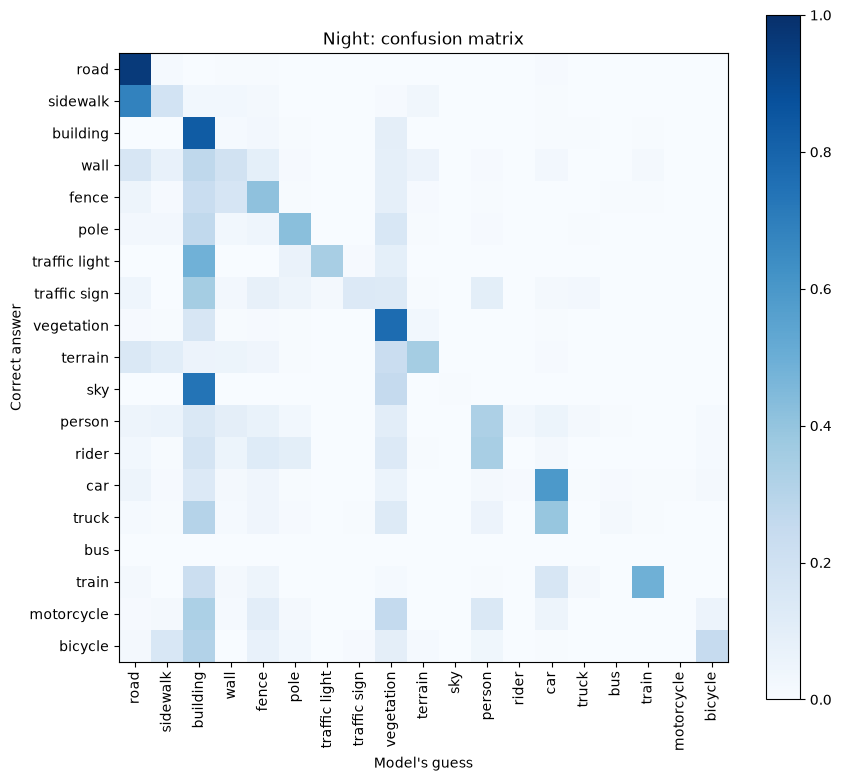

In [22]:
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(19))
ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(19))
ax.set_yticklabels(class_names)
ax.set_xlabel("Model's guess")
ax.set_ylabel("Correct answer")
ax.set_title("Night: confusion matrix")
fig.colorbar(im)
plt.tight_layout()
plt.savefig("../reports/figures/week2_confusion_night.png", dpi=150)
plt.show()

In [23]:
# score every night image and show the 3 worst

from weather_shift.metrics import image_miou

night = get_pairs("../data", "acdc", "night")
scores =[]
for image_path, label_path in tqdm(night):
    image = Image.open(image_path).convert("RGB")
    pred,_ = predict(image, processor, model)
    scores.append(image_miou(load_label(label_path), pred))

100%|██████████| 106/106 [00:57<00:00,  1.84it/s]


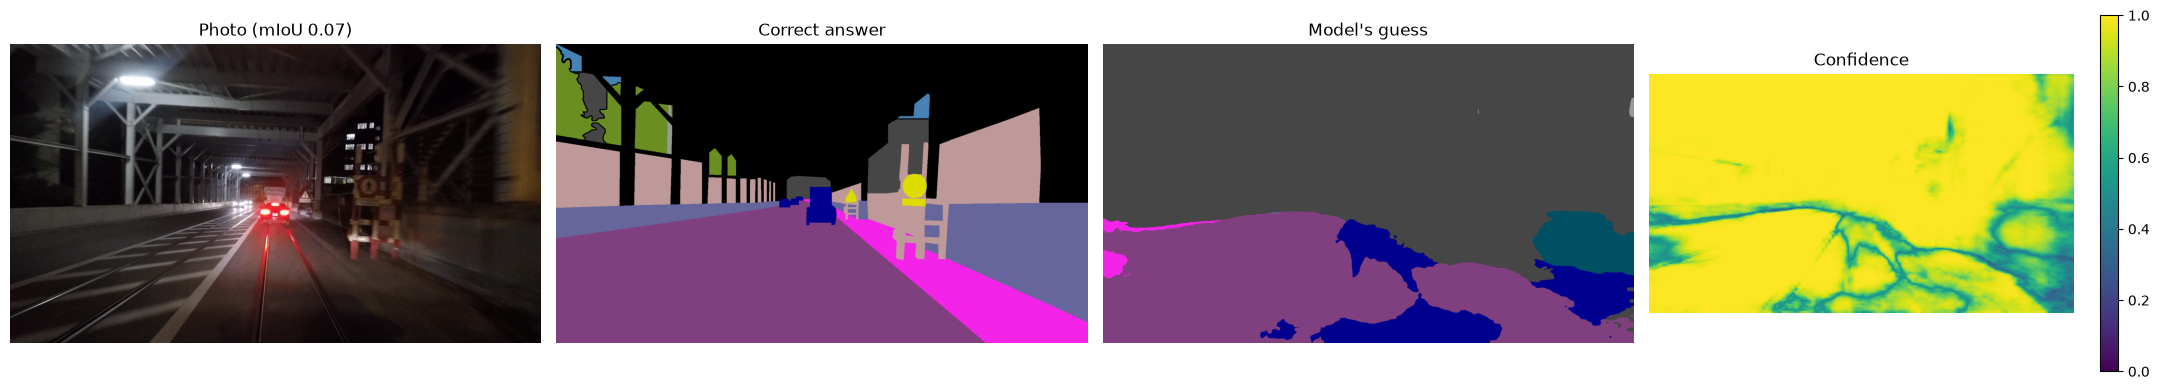

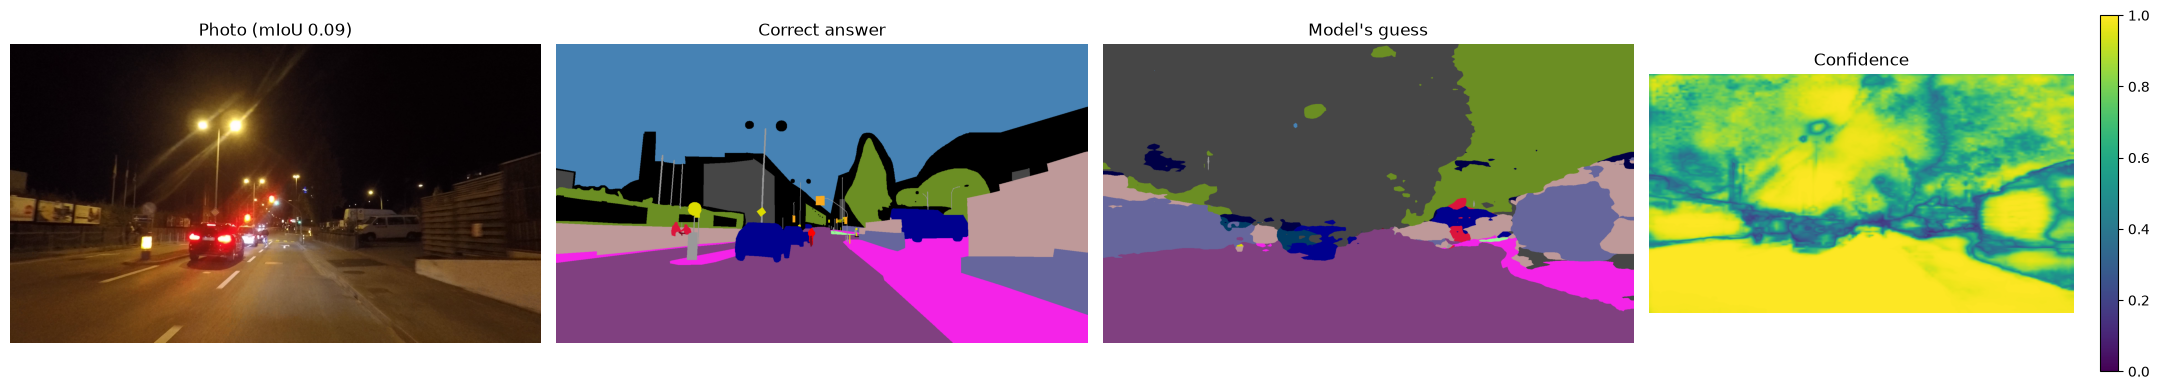

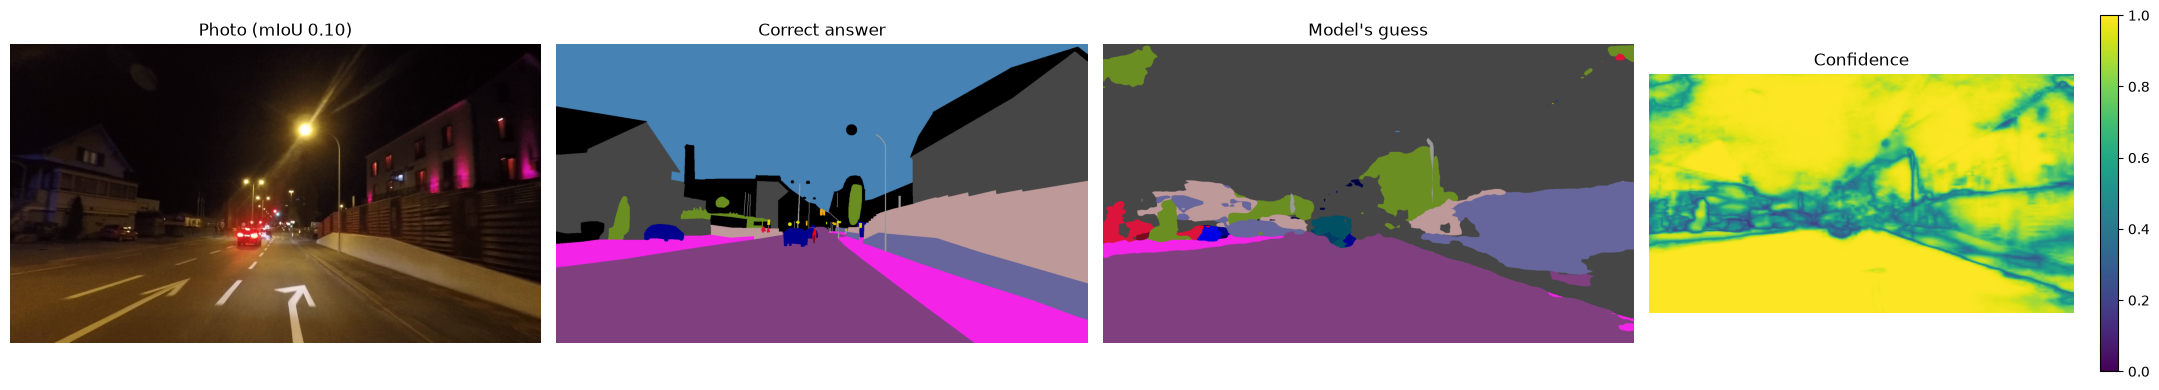

In [24]:
worst = np.argsort(scores)[:3]
for i in worst:
    image_path , label_path = night[i]
    image = Image.open(image_path).convert("RGB")
    label = load_label(label_path)
    pred, conf = predict(image, processor, model)

    fig, axes = plt.subplots(1, 4, figsize=(22, 4))
    axes[0].imshow(image)
    axes[0].set_title(f"Photo (mIoU {scores[i]:.2f})")
    axes[1].imshow(palette_ext[np.where(label == 255, 19, label)])
    axes[1].set_title("Correct answer")
    axes[2].imshow(palette[pred])
    axes[2].set_title("Model's guess")
    im = axes[3].imshow(conf, cmap="viridis", vmin=0, vmax=1)
    axes[3].set_title("Confidence")
    fig.colorbar(im, ax=axes[3])
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"../reports/figures/week2_night_worst_{i}.png", dpi=120)
    plt.show()